In [7]:
import os 
for root, dirs, files in os.walk('/kaggle/input/datasets/solesensei/solesensei_bdd100k'):
    for f in files:
        if f.endswith('.json'):
            print(os.path.join(root, f))

/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k_labels_release/bdd100k/labels/bdd100k_labels_images_val.json
/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k_labels_release/bdd100k/labels/bdd100k_labels_images_train.json


To find the files.

In [17]:
import json
VAL_JSON = '/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k_labels_release/bdd100k/labels/bdd100k_labels_images_val.json'
IMG_DIR  = '/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/val'

with open(VAL_JSON) as f:
    data = json.load(f)          # list of images

print(len(data), "images")
print(data[0].keys())            # what fields each image has
print(data[0]['labels'][:2])     # first 2 labels of image 0

10000 images
dict_keys(['name', 'attributes', 'timestamp', 'labels'])
[{'category': 'traffic sign', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'none'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 1000.698742, 'y1': 281.992415, 'x2': 1040.626872, 'y2': 326.91156}, 'id': 0}, {'category': 'traffic sign', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'none'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 214.613695, 'y1': 172.190058, 'x2': 274.505889, 'y2': 229.586743}, 'id': 1}]


To load the labels.

In [18]:
import pandas as pd
rows = []
for img in data:                         # each image
    for lab in img.get('labels', []):    # each object in it
        rows.append({'image': img['name'],
                     'category': lab['category'],
                     'has_box': 'box2d' in lab})
df = pd.DataFrame(rows)
df['category'].value_counts()

category
car              102506
lane              75730
traffic sign      34908
traffic light     26885
drivable area     17981
person            13262
truck              4245
bus                1597
bike               1007
rider               649
motor               452
train                15
Name: count, dtype: int64

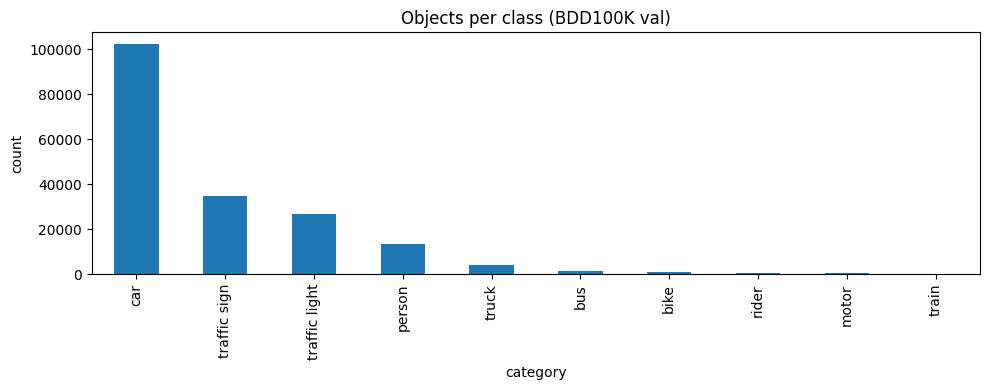

In [19]:
import matplotlib.pyplot as plt
counts = df[df.has_box]['category'].value_counts()
counts.plot(kind='bar', figsize=(10,4), title='Objects per class (BDD100K val)')
plt.ylabel('count'); plt.tight_layout()
plt.savefig('class_balance.png'); plt.show()

Class balance sheet

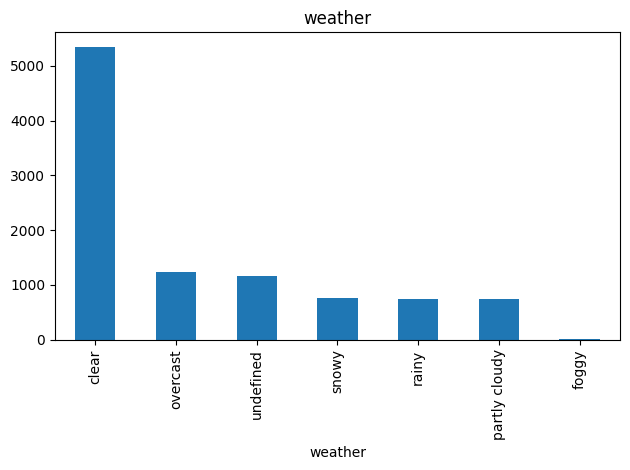

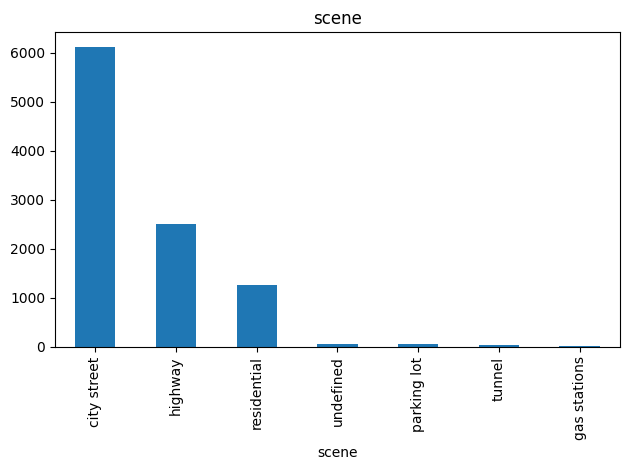

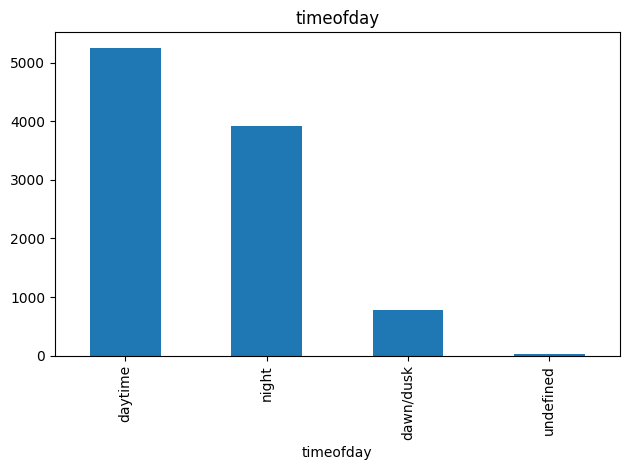

In [20]:
attrs = pd.DataFrame([img['attributes'] for img in data])
for col in ['weather', 'scene', 'timeofday']:
    attrs[col].value_counts().plot(kind='bar', title=col)
    plt.tight_layout(); plt.savefig(f'{col}.png'); plt.show()

Weather, scene, and time of day

In [21]:
   import os
   target = data[0]['name']
   for root, dirs, files in os.walk('/kaggle/input/datasets/solesensei/solesensei_bdd100k'):
       if target in files:
           print(root)
           break

/kaggle/input/datasets/solesensei/solesensei_bdd100k/bdd100k/bdd100k/images/100k/val


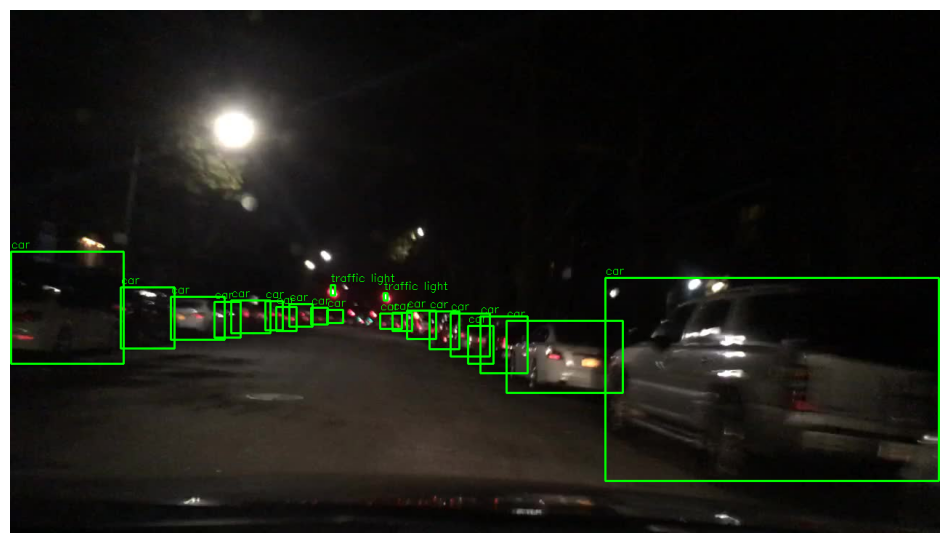

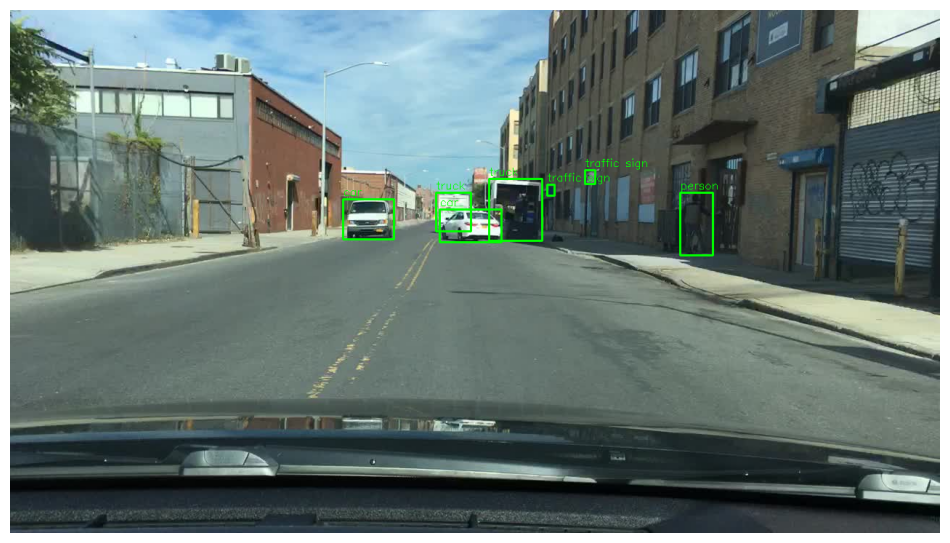

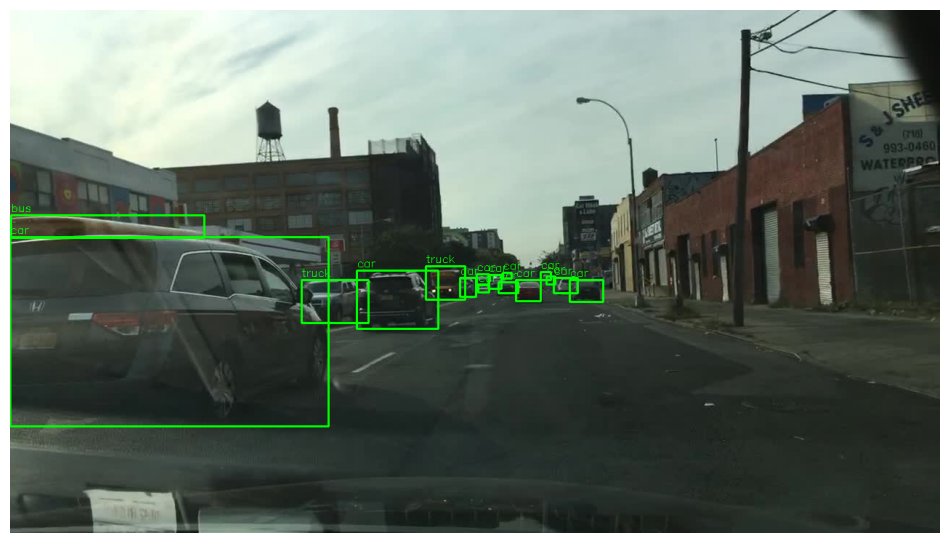

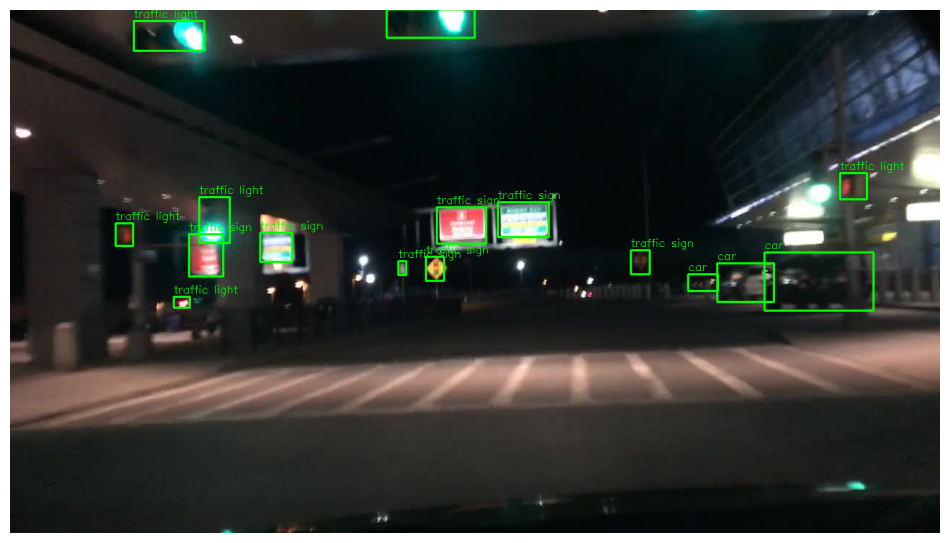

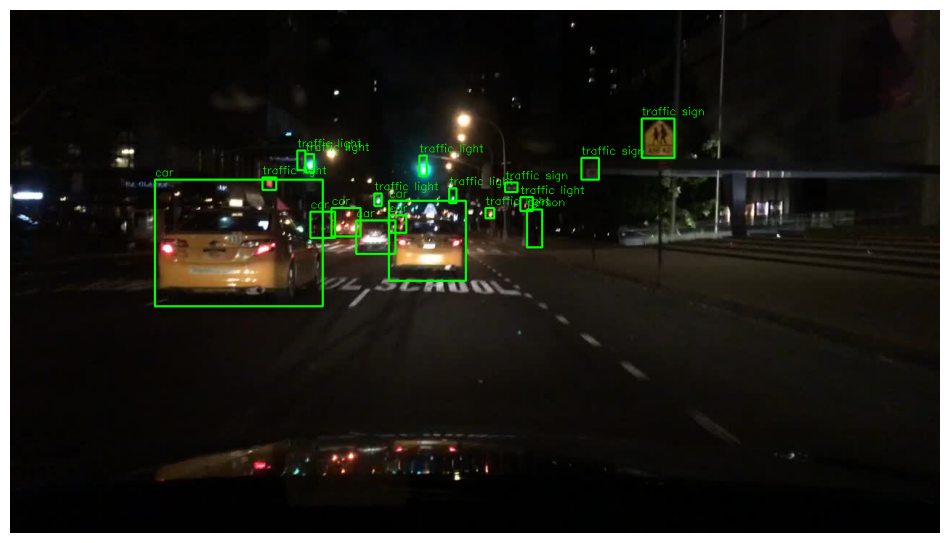

In [22]:
import cv2, random
for img in random.sample(data, 5):
    im = cv2.imread(os.path.join(IMG_DIR, img['name']))
    for lab in img['labels']:
        if 'box2d' in lab:
            b = lab['box2d']
            p1, p2 = (int(b['x1']), int(b['y1'])), (int(b['x2']), int(b['y2']))
            cv2.rectangle(im, p1, p2, (0,255,0), 2)
            cv2.putText(im, lab['category'], (p1[0], p1[1]-5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1)
    plt.figure(figsize=(12,7))
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))  # OpenCV uses BGR, matplotlib RGB
    plt.axis('off'); plt.show()

Draw boxes on 5 random images

count    10000.000000
mean        18.552600
std          9.596064
min          3.000000
25%         11.000000
50%         17.000000
75%         24.000000
max         66.000000
dtype: float64


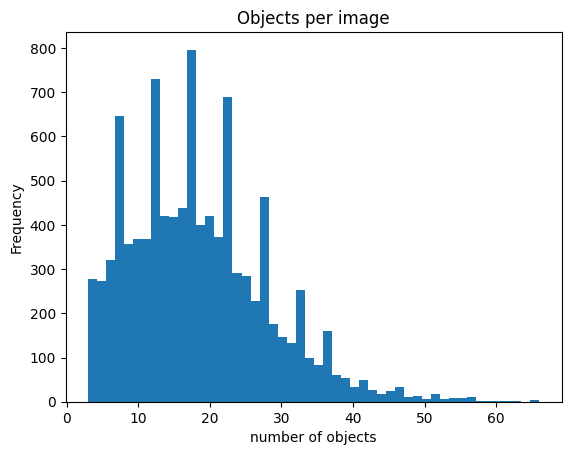

In [23]:
per_img = df[df.has_box].groupby('image').size()   # objects per image
print(per_img.describe())                            # mean, min, max...
per_img.plot(kind='hist', bins=50, title='Objects per image')
plt.xlabel('number of objects'); plt.savefig('objects_per_image.png'); plt.show()

0.5537175382426183


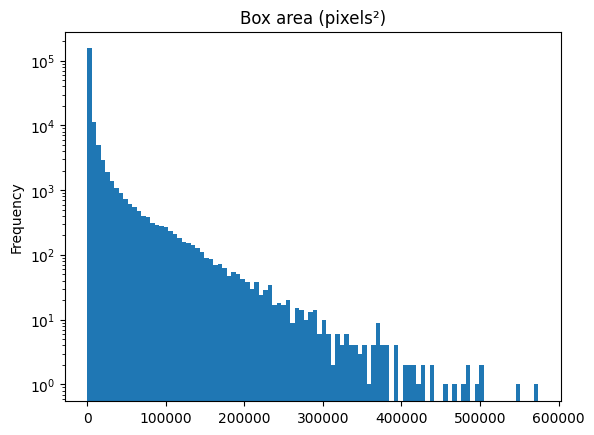

In [24]:
sizes = []
for img in data:
    for lab in img['labels']:
        if 'box2d' in lab:
            b = lab['box2d']
            w, h = b['x2'] - b['x1'], b['y2'] - b['y1']
            sizes.append({'category': lab['category'], 'area': w * h})
sizes = pd.DataFrame(sizes)

print((sizes['area'] < 32*32).mean())   # fraction of "small" objects
sizes['area'].plot(kind='hist', bins=100, log=True, title='Box area (pixels²)')
plt.savefig('box_sizes.png'); plt.show()